# PySlyde tutorial: from a whole-slide image to tiles and features

Digital pathology models rarely work on a whole-slide image (WSI) directly: a single slide can be
100,000 × 100,000 pixels, far larger than a GPU can process at once, and most of it is empty glass.
The usual pre-processing pipeline is therefore to find the tissue, cut it into small tiles, keep the
informative ones and turn them into something a model can learn from: images, label masks or
feature vectors. This notebook walks through that pipeline with PySlyde:

1. open a WSI and inspect its resolution levels,
2. detect tissue automatically (no annotations needed),
3. read pathologist-style annotations in every supported format,
4. turn annotations into label masks and extract annotated regions,
5. tile the slide, filter out background and inspect tile-level masks,
6. stain-normalise tiles (optional),
7. extract deep-learning features and reduce them with PCA,
8. save tiles, masks and features for model training,
9. stitch tiles back into a slide-level image.

| Output | Typical downstream use |
|---|---|
| Tissue mask / border | Restrict all later steps to tissue; quality control |
| Annotation masks (slide, region or tile level) | Ground truth for segmentation models; tile labels for classification |
| Filtered tiles (PNG, LMDB, RocksDB) | Training data for tile-level CNNs / vision transformers |
| Tile feature vectors | Slide-level prediction with multiple-instance learning (MIL), clustering, retrieval |
| Channel statistics, class weights | Input normalisation and class balancing when training |
| Stitched images | Mapping tile-level outputs (e.g. predictions) back onto the slide |

**Data.** The notebook runs on the PySlyde [example dataset](https://pyslyde.readthedocs.io/en/latest/example_data.html):
`CMU-1-Small-Region.svs` from the OpenSlide test data (CC0, 1.9 MB, downloaded once and
checksum-verified), a small H&E-stained region, with *synthetic* `tissue` and `epithelium`
annotations shipped with PySlyde. To run it on your own data, set the environment variable
`PYSLYDE_DATA_DIR` to a folder containing `wsi/` and `annotations/` before starting Jupyter.

Install PySlyde with its optional extras (`pip install "pyslyde[all]"`), plus the OpenSlide
library (see the installation guide). The whole notebook runs in about a minute on a laptop CPU.
The only extra download is the torchvision ResNet-18 weights used in the feature-extraction section.

## Setup

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import openslide

import pyslyde
from pyslyde import Annotations, Slide, Stitching, WSIParser
from pyslyde.datasets import example_data_dir
from pyslyde.masks.level0 import Level0Mask
from pyslyde.normalization.factory import make_normalizer
from pyslyde.util import filters
from pyslyde.util.utilities import (
    TissueDetect,
    calculate_std_mean,
    calculate_weights,
    coord_to_name,
    mask2rgb,
)

plt.rcParams["figure.dpi"] = 80

print("PySlyde", pyslyde.__version__, "| OpenSlide", openslide.__library_version__)

PySlyde 0.1.0 | OpenSlide 4.0.1


In [2]:
DATA_DIR = example_data_dir()  # honours $PYSLYDE_DATA_DIR
WSI_PATH = next((DATA_DIR / "wsi").iterdir())
ANN_DIR = DATA_DIR / "annotations"

OUTPUT_DIR = Path("tutorial_output")  # everything this notebook writes goes here
OUTPUT_DIR.mkdir(exist_ok=True)

THUMB_SIZE = (555, 742)  # (width, height) used for all slide-level plots

print("slide:", WSI_PATH.name)
print("annotations:", sorted(p.name for p in ANN_DIR.iterdir()))

slide: CMU-1-Small-Region.svs
annotations: ['example.csv', 'example.geojson', 'example_asap.xml', 'example_custom.json', 'example_imagej.xml', 'example_qupath.json']


## 1. Whole-slide images with `Slide`

WSI files store the same image at several resolutions, called a *pyramid*. Level 0 is the full
scanning resolution, and each further level is a downsampled copy that is quicker to read. Two
properties tell you the physical scale: the *objective power* (e.g. 20× or 40×, the microscope
magnification used for scanning) and the *microns per pixel* (mpp). Choosing the level and tile
size together decides how much tissue each tile shows, which matters because models are trained
at a specific magnification.

`Slide` subclasses `openslide.OpenSlide`, so all OpenSlide properties and methods are available,
plus annotation masks, borders and region extraction.

dimensions (w, h): (2220, 2967)
pyramid levels:    1 ((2220, 2967),)
objective power:   20
microns per pixel: 0.499


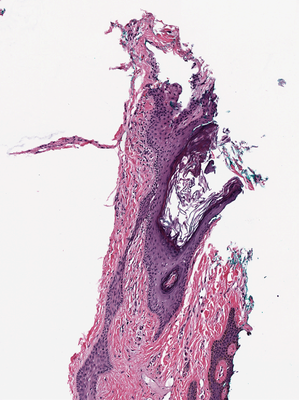

In [3]:
slide = Slide(str(WSI_PATH))
print("dimensions (w, h):", slide.dims)
print("pyramid levels:   ", slide.level_count, slide.level_dimensions)
print(
    "objective power:  ", slide.properties.get(openslide.PROPERTY_NAME_OBJECTIVE_POWER)
)
print("microns per pixel:", slide.properties.get(openslide.PROPERTY_NAME_MPP_X))
thumb = np.array(slide.get_thumbnail(THUMB_SIZE).convert("RGB"))
slide.get_thumbnail((400, 400))

This example is a small single-level crop (20×, about 0.5 µm per pixel). Real slides typically
have three or four levels and are several gigabytes.

## 2. Tissue detection

Before anything else, it is useful to know where the tissue is. Everything outside it is glass,
dust or pen marks, and processing it wastes time and adds uninformative tiles to the training data.
`TissueDetect` finds tissue automatically, without any annotations: it thresholds a low-resolution
thumbnail (Otsu's method) and cleans the result with morphological operations. It accepts a path,
an `OpenSlide` object or a NumPy image, and returns a binary mask (1 = tissue) and the bounding box
of the tissue.

tissue fraction: 0.282
tissue border: ((0, 2124), (0, 2967))


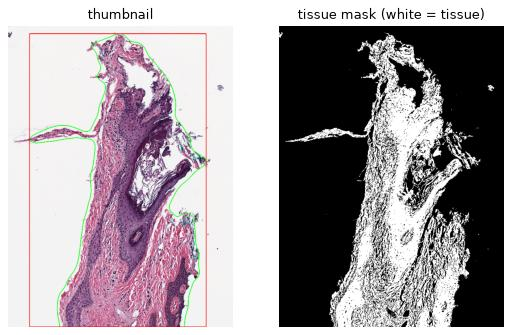

In [4]:
detector = TissueDetect(str(WSI_PATH))
tissue_mask = detector.detect_tissue()  # full-resolution binary mask
tissue_border = detector.border()  # ((x_min, x_max), (y_min, y_max))
print("tissue fraction:", round(float(tissue_mask.mean()), 3))
print("tissue border:", tissue_border)

fig, axes = plt.subplots(1, 2, figsize=(8, 5))
axes[0].imshow(cv2.resize(detector.tissue_thumbnail, THUMB_SIZE))
axes[0].set_title("thumbnail")
axes[1].imshow(cv2.resize(tissue_mask, THUMB_SIZE), cmap="gray")
axes[1].set_title("tissue mask (white = tissue)")
for ax in axes:
    ax.axis("off")
plt.show()

The tissue mask is used below to drop background tiles, and the border to limit where tiles are
generated.

### Separate pieces of tissue

A slide often holds more than one piece of tissue, for example several sections of the same
biopsy or the cores of a tissue microarray. `detect_components` finds the largest separate pieces
at a given pyramid level and returns an image and a level-0 bounding box for each, so they can be
processed or saved individually. This slide has a single level, so we use `level=0`.

component borders: [[(1640, 1888), (1081, 1412)], [(69, 1888), (83, 2967)]]


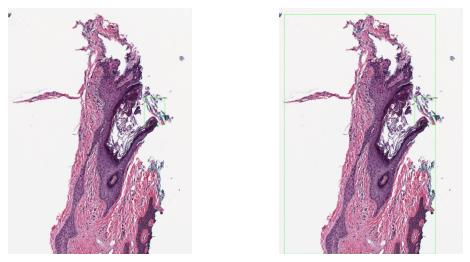

In [5]:
components, borders = slide.detect_components(level=0, num_component=2)
print("component borders:", borders)

fig, axes = plt.subplots(1, len(components), figsize=(4 * len(components), 4))
for ax, comp in zip(np.atleast_1d(axes), components):
    ax.imshow(comp)
    ax.axis("off")
plt.show()

## 3. Annotations in six formats

Annotations are polygons drawn on the slide, usually by a pathologist, to outline regions of
interest such as tumour, stroma or, here, `tissue` and `epithelium`. They are the ground truth for
supervised learning. Each annotation tool saves them in its own format, so PySlyde reads QuPath,
ImageJ, ASAP, GeoJSON, CSV and a custom JSON format into the same in-memory representation:
`{label: [polygon, ...]}` with level-0 pixel coordinates.

The example dataset contains the same polygons in every format. They are synthetic: the `tissue`
polygon was generated by thresholding, much like the tissue detection above, and the `epithelium`
polygons outline haematoxylin-rich (dark purple) regions within it.

In [6]:
sources = {
    "geojson": "example.geojson",
    "csv": "example.csv",
    "qupath": "example_qupath.json",
    "asap": "example_asap.xml",
    "imagej": "example_imagej.xml",
    "json": "example_custom.json",
}
anns = {
    src: Annotations(str(ANN_DIR / fname), source=src) for src, fname in sources.items()
}

for src, a in anns.items():
    summary = {label: len(polys) for label, polys in a.annotations.items()}
    print(f"{src:8s} polygons per label: {summary}")

geojson  polygons per label: {'tissue': 1, 'epithelium': 3}
csv      polygons per label: {'tissue': 1, 'epithelium': 3}
qupath   polygons per label: {'tissue': 1, 'epithelium': 3}
asap     polygons per label: {'tissue': 1, 'epithelium': 3}
imagej   polygons per label: {'tissue': 1, 'epithelium': 3}
json     polygons per label: {'tissue': 1, 'epithelium': 3}


Each label gets a stable integer ID, used as the pixel value in masks (0 is background):

In [7]:
annotations = anns["geojson"]
annotations.class_key

{'epithelium': 1, 'tissue': 2}

To keep label colours consistent in every plot, we define one colour per label and a helper that
draws a legend. `mask2rgb` colours each label ID the same way as long as it gets the same
`n_classes` (number of labels + 1 for background):

In [8]:
N_CLASSES = len(annotations.class_key) + 1


def label_colour(label_id):
    return mask2rgb(np.array([[label_id]]), n_classes=N_CLASSES)[0, 0]


def add_legend(ax):
    handles = [
        mpatches.Patch(color=label_colour(i), label=f"{i} = {name}")
        for name, i in annotations.class_key.items()
    ]
    ax.legend(handles=handles, loc="lower right", fontsize=8, framealpha=0.9)

Labels can be renamed, for example to harmonise names between annotators or datasets, and
annotations exported as a table or another format:

In [9]:
renamed = Annotations(str(ANN_DIR / "example.geojson"), source="geojson")
renamed.rename_labels({"epithelium": "epi"})
print(renamed.class_key)

annotations.df.head()

{'epithelium': 1, 'tissue': 2}


,label,polygon_id,vertex_id,x,y
0,tissue,0,0,1070,78
1,tissue,0,1,1066,110
2,tissue,0,2,1056,112
3,tissue,0,3,1046,142
4,tissue,0,4,976,144


In [10]:
annotations.save_csv(str(OUTPUT_DIR / "annotations.csv"), overwrite=True)
annotations.save_geojson(str(OUTPUT_DIR / "annotations.geojson"), overwrite=True)
sorted(p.name for p in OUTPUT_DIR.iterdir())

['annotations.csv', 'annotations.geojson']

## 4. Annotation masks and regions

Models do not read polygons; they need a *label mask*, an image the same shape as the slide (or a
downsampled copy) where each pixel holds the ID of its label. Attach the annotations to the slide,
then rasterise them with `generate_mask`, which takes either an output `size` (width, height) or a
pyramid `level`. Where labels overlap, as here where the epithelium lies inside the tissue
annotation, the overlapping pixels keep the epithelium ID.

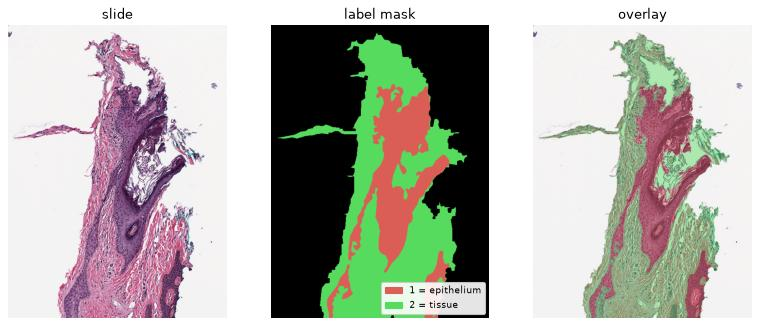

In [11]:
slide = Slide(str(WSI_PATH), annotations=annotations)
mask = slide.generate_mask(size=THUMB_SIZE)
mask_rgb = mask2rgb(mask, n_classes=N_CLASSES)
overlay = np.dstack(
    [mask_rgb, 0.45 * (mask > 0)]
)  # transparent where there is no label

fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes[0].imshow(thumb)
axes[0].set_title("slide")
axes[1].imshow(mask_rgb)
axes[1].set_title("label mask")
add_legend(axes[1])
axes[2].imshow(thumb)
axes[2].imshow(overlay)
axes[2].set_title("overlay")
for ax in axes:
    ax.axis("off")
plt.show()

Restrict a mask to some labels (by name or ID), for example to train a model on one tissue type,
and get the bounding border of the annotations:

In [12]:
epithelium = slide.generate_mask(size=THUMB_SIZE, labels=["epithelium"])
print("epithelium pixels:", int((epithelium > 0).sum()))
print("annotation border [(x_min, x_max), (y_min, y_max)]:", slide.get_border())

epithelium pixels: 53060
annotation border [(x_min, x_max), (y_min, y_max)]: [(0, 2090), (0, 2967)]


`generate_region` returns a full-resolution RGB region and its aligned annotation mask (level-0
coordinates). This is handy for inspecting an area in detail or for building a small
image/mask pair for segmentation:

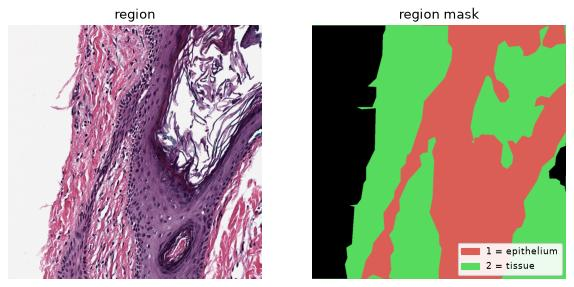

In [13]:
region, region_mask = slide.generate_region(level=0, x=(600, 1600), y=(1200, 2200))

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(region)
axes[0].set_title("region")
axes[1].imshow(mask2rgb(region_mask, n_classes=N_CLASSES))
axes[1].set_title("region mask")
add_legend(axes[1])
for ax in axes:
    ax.axis("off")
plt.show()

`save` writes the slide-level mask (`masks/*.npy`), a colour visualisation (`vis/*.png`) and
metadata such as the label IDs (`meta/*.json`) in one call, so a mask can be reloaded later
without the original annotation file:

In [14]:
slide.save(str(OUTPUT_DIR / "slide"), size=THUMB_SIZE, overwrite=True)

{'mask': 'tutorial_output/slide/masks/CMU-1-Small-Region.npy',
 'vis': 'tutorial_output/slide/vis/CMU-1-Small-Region.png',
 'meta': 'tutorial_output/slide/meta/CMU-1-Small-Region.json'}

## 5. Tiling with `WSIParser`

Deep-learning models take small, fixed-size images, typically 224 or 256 pixels square. `WSIParser`
lays a grid of tiles over a border at a given pyramid level. Here we tile the tissue border found
in section 2 at level 0 with 256-pixel tiles, i.e. about 128 µm of tissue per tile. The `stride`
is the step between tiles: equal to the tile size for non-overlapping tiles, smaller for
overlapping ones. Tile coordinates are the level-0 `(x, y)` of each tile's top-left corner.

tiles: 88


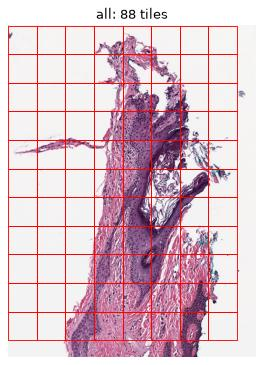

In [15]:
TILE = 256
parser = WSIParser(slide=slide, tile_dim=TILE, border=tissue_border, level=0)
# edge_cases=True drops tiles that would extend past the border / slide edge
print("tiles:", parser.tiler(stride=TILE, edge_cases=True))


def show_tiles(parser, title):
    scale = THUMB_SIZE[0] / slide.dims[0]
    fig, ax = plt.subplots(figsize=(4, 5.4))
    ax.imshow(thumb)
    for x, y in parser.tiles:
        square = mpatches.Rectangle(
            (x * scale, y * scale),
            TILE * scale,
            TILE * scale,
            fill=False,
            edgecolor="red",
            linewidth=0.8,
        )
        ax.add_patch(square)
    ax.set_title(f"{title}: {parser.number} tiles")
    ax.axis("off")
    plt.show()


show_tiles(parser, "all")

### Filtering tiles

Many of these tiles are mostly background. PySlyde offers two complementary filters. Each removes
tiles from the parser, so later steps only see the tiles that are kept.

`filter_by_func` applies any function that takes a tile and returns `True` for tiles to drop. A
quick first pass is to drop bright tiles, since glass is close to white (mean intensity above 220
out of 255):

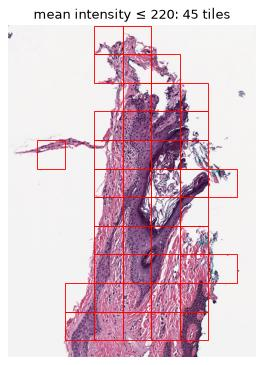

In [16]:
parser.filter_by_func(filters.tile_intensity, threshold=220)
show_tiles(parser, "mean intensity ≤ 220")

`filter_by_mask` keeps tiles in which a whole-slide mask covers at least a given fraction of the
tile. With the tissue mask from section 2 (wrapped as a level-0 mask), this removes the remaining
tiles that are mostly background, such as faint or partly empty tiles that passed the intensity
filter. With an annotation mask instead, the same call keeps only tiles of a given label, e.g.
epithelium.

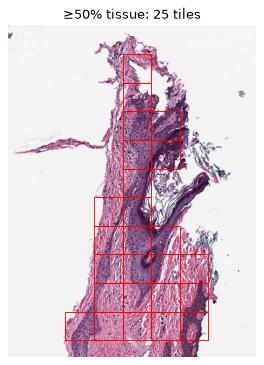

In [17]:
tissue = Level0Mask(tissue_mask.astype(np.uint8))
parser.filter_by_mask(tissue, labels=1, threshold=0.5)
show_tiles(parser, "≥50% tissue")

Look at a few of the tiles that are kept:

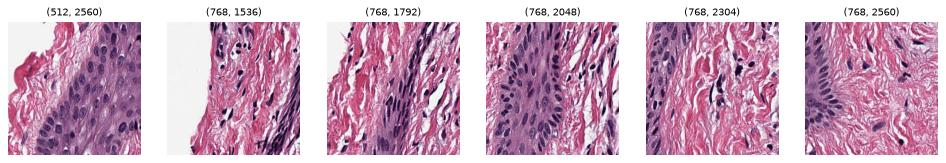

In [18]:
fig, axes = plt.subplots(1, 6, figsize=(15, 2.6))
for ax, ((x, y), tile) in zip(axes, parser.extract_tiles()):
    ax.imshow(tile)
    ax.set_title(f"({x}, {y})", fontsize=9)
    ax.axis("off")
plt.show()

### Tile-level annotation masks

`extract_masks` returns, for each tile, the matching crop of a whole-slide mask. With the
annotation mask, each tile gets a label mask of the same size: these image/mask pairs are the
training data for a segmentation model, and the majority label of each mask can serve as a
tile label for a classification model. The colours are the same as in section 4; a tile can
contain both labels or only one of them.

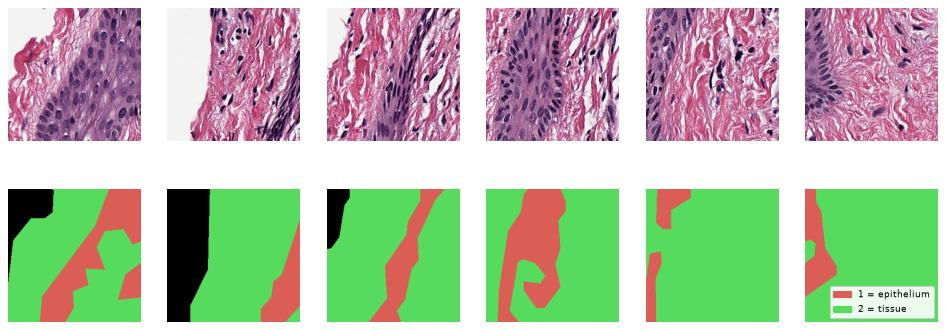

In [19]:
annotation_mask = Level0Mask(slide.generate_mask(level=0).astype(np.uint8))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
pairs = zip(parser.extract_tiles(), parser.extract_masks(annotation_mask))
for i, ((_, tile), (_, tile_mask)) in enumerate(pairs):
    if i == 6:
        break
    axes[0, i].imshow(tile)
    axes[1, i].imshow(mask2rgb(tile_mask, n_classes=N_CLASSES))
    axes[0, i].axis("off")
    axes[1, i].axis("off")
add_legend(axes[1, -1])
plt.show()

## 6. Stain normalisation (optional)

H&E-stained slides vary in colour between hospitals, scanners and staining batches. A model trained
on slides from one centre can perform worse on another just because of these colour differences.
Stain normalisation maps every tile to the colour profile of a reference (*target*) image.

It is optional. It matters most when combining data from several sources, or when applying a model
to data from a new site. Colour augmentation during training is a common alternative, and large
pathology foundation models (section 7) are often fairly robust to colour variation. On data from a
single site it is often unnecessary.

Normalisation is applied when tiles are extracted, not to the whole slide, so it does not change
which tiles are selected: tissue detection and filtering above work on the raw colours. PySlyde
implements the Macenko, Reinhard and Vahadane methods. Fit a normaliser on a target tile, pass it
to `WSIParser`, then request `normalize=True` when extracting tiles. The target should be a
well-stained, representative tile; here we simply use the first tile kept above.

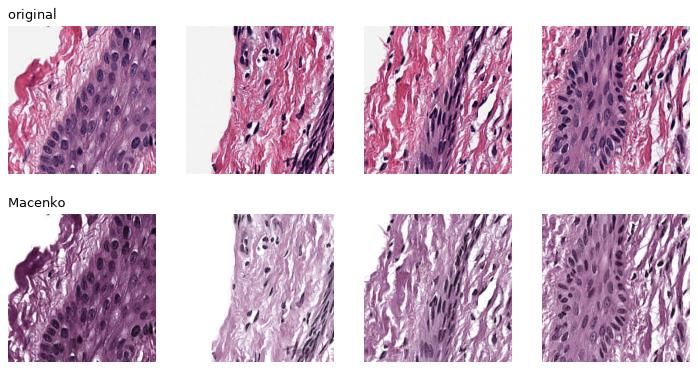

In [20]:
target_tile = next(parser.extract_tiles())[1]
normalizer = make_normalizer("macenko").fit(target_tile)

norm_parser = WSIParser(
    slide=slide,
    tile_dim=TILE,
    border=tissue_border,
    level=0,
    stain_normalizer=normalizer,
)
norm_parser.tiles = parser.tiles[:4]

fig, axes = plt.subplots(2, 4, figsize=(11, 5.6))
raw_tiles = norm_parser.extract_tiles()
norm_tiles = norm_parser.extract_tiles(normalize=True)
for i, ((_, raw), (_, norm)) in enumerate(zip(raw_tiles, norm_tiles)):
    axes[0, i].imshow(raw)
    axes[1, i].imshow(norm)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
axes[0, 0].set_title("original", loc="left")
axes[1, 0].set_title("Macenko", loc="left")
plt.show()

The tiles all come from one slide, so the change is subtle here; the effect is larger across
slides from different sources.

## 7. Feature extraction

A common way to use tiles is to pass each one through a pretrained neural network and keep its
internal representation, a *feature vector* (or embedding) of a few hundred to a few thousand
numbers summarising the tile's appearance. A slide then becomes a set of feature vectors, which is
much smaller than the images. These feature sets are the input to multiple-instance learning (MIL)
models that predict slide-level labels such as cancer subtype, mutation status or survival, and can
also be clustered or searched to find similar tissue.

`extract_features` runs a model on every tile and yields `((x, y), feature_vector)`.
Torchvision models (`resnet18`, `resnet50`, `vgg16`) download ImageNet weights on first use.
Pathology foundation models, trained on millions of pathology tiles, usually give more
informative features: `uni`, `uni2`, `virchow`, `virchow2`, `gigapath`, `hoptimus0`, `hoptimus1`,
`phikon`, `phikon2`, `transpath` and `pathfm` are supported, several of which are gated on Hugging
Face and need a token. If you use a normaliser, pass it to the parser as in section 6 before
extracting features.

In [21]:
parser.sample_tiles(n=24, seed=0)  # keep the example fast
features = dict(parser.extract_features(model_name="resnet18"))
coords = np.array(list(features))
X = np.stack(list(features.values()))
print("feature matrix:", X.shape)  # (tiles, features per tile)

feature matrix: (24, 512)


Feature vectors are high-dimensional. Principal component analysis (PCA, `pyslyde.util.pca`)
reduces them to a few components, which helps visualise the structure of the data or shrink the
features before downstream modelling. Each point below is a tile; tiles with similar appearance
end up close together:

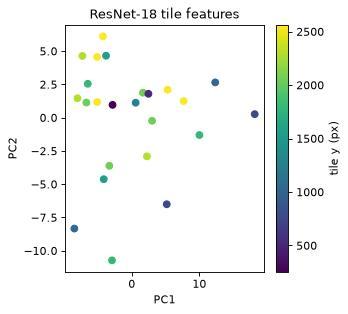

In [22]:
from pyslyde.util.pca import PCAConfig, fit_pca_from_parser

pca = fit_pca_from_parser(
    iter(features.items()), config=PCAConfig(n_components=2, method="full")
)
Z = pca.transform(X)

plt.figure(figsize=(4, 4))
plt.scatter(Z[:, 0], Z[:, 1], c=coords[:, 1], cmap="viridis")
plt.colorbar(label="tile y (px)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("ResNet-18 tile features")
plt.show()

## 8. Saving outputs

How to store tiles depends on the scale of the project. A folder of PNG files is easy to inspect
and fine for small datasets. Key-value databases such as LMDB or RocksDB store all tiles of a
dataset in one file with fast random access, which avoids slow file-system access when a training
loop reads millions of tiles. Features are saved as one `.npy` file per tile, named by its
coordinates, ready for MIL training:

In [23]:
parser.save_tiles(tile_path=str(OUTPUT_DIR / "tiles"), label_csv=True)
parser.to_lmdb(
    parser.extract_tiles(), db_path=str(OUTPUT_DIR / "tiles.lmdb"), map_size=1024**3
)
parser.feat_to_disk(
    parser.extract_features(model_name="resnet18"), path=str(OUTPUT_DIR / "features")
)

n_tiles = len(list((OUTPUT_DIR / "tiles").iterdir()))
n_features = len(list((OUTPUT_DIR / "features").iterdir()))
print(n_tiles, "tile PNGs |", n_features, "feature files")

db path and map_size: tutorial_output/tiles.lmdb 1073741824
Beginning writing to lmdb ...
Finished writing to lmdb (24 items).
Beginning writing to disk...


Finished writing to disk (24 items).
24 tile PNGs | 24 feature files


Neural networks train better when their inputs are standardised. `calculate_std_mean` computes the
per-channel mean and standard deviation of the saved tiles, to be used in the input normalisation
step of a training pipeline:

In [24]:
mean, std = calculate_std_mean(str(OUTPUT_DIR / "tiles"))

total number pixels: 1572864


mean: [0.58437588 0.44534164 0.64227313], std: [0.21058063 0.26318875 0.24129613]


### Tile masks and class weights

For segmentation training, save the annotation mask of each tile, named by its coordinates like
the tile images, so each image can be paired with its mask. Labels are rarely balanced, and a model
trained on unbalanced data tends to ignore rare classes. Here, because we kept only tiles that are
mostly tissue, background has become the rare class. `calculate_weights` computes inverse-frequency class weights (background
first) that can be passed to the loss function so that rare classes count more:

In [25]:
mask_dir = OUTPUT_DIR / "tile_masks"
mask_dir.mkdir(exist_ok=True)
for (x, y), m in parser.extract_masks(annotation_mask):
    cv2.imwrite(str(mask_dir / f"{coord_to_name(x, y)}.png"), m.astype(np.uint8))

weights = calculate_weights(str(OUTPUT_DIR / "tile_masks"), num_cls=N_CLASSES)
weights

Calculating weights
[np.float64(0.02708880106608073), np.float64(0.4008992513020833), np.float64(0.5720119476318359)]
[np.float64(36.915624193207684), np.float64(2.494392286221771), np.float64(1.7482152324615954)]


[np.float64(36.915624193207684),
 np.float64(2.494392286221771),
 np.float64(1.7482152324615954)]

## 9. Stitching tiles back together

`Stitching` reassembles saved tiles, whose filenames encode their coordinates, into one image. This
is mainly used to map tile-level results back onto the slide, for example to build a heatmap of a
model's predictions, and to check that a set of tiles covers the intended area. With a contiguous
grid of tiles, it reconstructs the tiled area of the slide:

completeness: 1.0


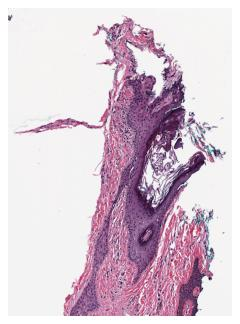

In [26]:
grid = WSIParser(slide=slide, tile_dim=TILE, border=tissue_border, level=0)
grid.tiler(stride=TILE, edge_cases=True)
grid.save_tiles(tile_path=str(OUTPUT_DIR / "grid_tiles"))

stitcher = Stitching(str(OUTPUT_DIR / "grid_tiles"), slide=slide, level=0)
canvas = stitcher.stitch(size=(512, 704))  # OpenCV channel order (BGR)
canvas = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
print("completeness:", stitcher.completeness())

plt.figure(figsize=(5, 5))
plt.imshow(canvas)
plt.axis("off")
plt.show()

## Next steps

* [Quick Start](https://pyslyde.readthedocs.io/en/latest/quickstart.html) - the shortest path from a slide to saved tiles
* [API reference](https://pyslyde.readthedocs.io/en/latest/api/index.html)
* [Mask to polygons with GeoPandas](geopandas_polygons.ipynb) - convert masks to GeoPandas polygons